# Major TOM

Major TOM is a global grid of cells of about 10 km, and a family of open Earth observation datasets keyed by those
cells. Any dataset built on the grid lines up with every other one: join them on the cell name, `grid_cell`.

The `majortom` package does each step of making and using such datasets:

    points or areas -> cells (majortom.cells) -> samples from public archives (majortom.build)
      -> a TACO dataset (majortom.release) -> published on source.coop or Hugging Face
      -> joined with weather and climate per cell (majortom.climate datasets) and with the Core datasets

| Part | What it does | Extra |
|---|---|---|
| `majortom.cells` | the grid: cells for points, boxes and polygons, at any spacing | none |
| `majortom.build` | one sample per cell from public archives, for optical, radar, elevation, land cover and other products (current list: section 4) | `build` (`gee` for Earth Engine) |
| `majortom.release` | samples to a TACO dataset (rumi or COG files, partitions, catalogue), and publishing | `release` |
| `majortom.climate` | weather and climate per cell from ERA5, ERA5-Land, CAMS, NOAA CPC, IMERG, Sentinel-5P | `climate` |
| `majortom.spec` | the sample window for any spacing and resolution; Core v1 corrections | none |
| readers (`read_row`, `filter_metadata`) | the Core datasets on Hugging Face | none |
| `majortom.embedder` | SigLIP, DINOv2 and SSL4EO embeddings of samples | `embed` |

<img src="https://raw.githubusercontent.com/ESA-PhiLab/Major-TOM/refactor/v1/docs/animations/out/gif0_workflow.gif" alt="Major TOM workflow: grid, footprint, archive query, read and cloud mask, rumi, TACO" width="720">

Paper: [Major TOM: Expandable Datasets for Earth Observation](https://arxiv.org/abs/2402.12095) (IGARSS 2024).
Code and documentation: [https://github.com/ESA-PhiLab/Major-TOM](https://github.com/ESA-PhiLab/Major-TOM).

## 1. Install

| Extra | Adds |
|---|---|
| (none) | grid, windows, Core readers: numpy, pandas, geopandas, shapely, pyproj, pyarrow, fsspec, rasterio |
| `build` | `majortom.build` on STAC archives (pystac-client, planetary-computer) |
| `gee` | the Earth Engine archive (earthengine-api) |
| `release` | `majortom.release`: rumi, taco-eo, boto3, huggingface_hub (Python 3.12 or later for the COG profile) |
| `climate` | `majortom.climate` builds: xarray, zarr, gcsfs, cdsapi |
| `torch`, `embed`, `viz` | the PyTorch dataset, the embedders, plotting |

The package is installed from GitHub until it is on PyPI.

In [ ]:
#@title Install
%pip install -q "majortom[build,release] @ git+https://github.com/ESA-PhiLab/Major-TOM@refactor/v1" matplotlib

In [2]:
import warnings
warnings.filterwarnings("ignore", message="Arrow output on a DB-API result")       # taco-eo, harmless
warnings.filterwarnings("ignore", message="Dataset has no geotransform")           # rasterio, Sentinel-3 swath files
warnings.filterwarnings("ignore", message="IProgress not found")                   # tqdm outside Jupyter widgets

## 2. The grid

The grid is defined by a spacing `d` (10 km for every published dataset) and two rules
([SPEC section 2](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/SPEC.md)):

- **Rows** are circles of constant latitude, `180° / n_rows` apart, with `n_rows = ceil(π · 6378.137 km / d)`
  (2,004 rows at 10 km). Row 0 starts at the equator; rows north are `U`, rows south are `D`.
- **Columns**: each row has its own number of columns, `ceil(2π · 6378.137 km · cos(latitude) / d)`, so cells stay
  about `d` wide. Towards the poles rows have fewer columns. Column 0 starts at 0° longitude; east is `R`, west `L`.

A cell is named after its south-west corner: `624U_29L` is row 624 north, column 29 west. At 10 km the grid has
5,113,745 cells.

<img src="https://raw.githubusercontent.com/ESA-PhiLab/Major-TOM/refactor/v1/docs/animations/out/gif1_grid.gif" alt="How the Major TOM grid is defined: rows in latitude, points per row, cells" width="640">

| Function or attribute | Gives |
|---|---|
| `cell_at(lon, lat, d=10)` | the cell containing a point |
| `cell_from_name("624U_29L", d=10)` | the cell with that name |
| `Cell(row, col, d=10)` | a cell from its signed row and column |
| `.name`, `.row`, `.col`, `.centroid`, `.n_cols` | name, position, midpoint (lon, lat), columns in its row |
| `.lon`, `.lat`, `.dlon`, `.dlat` | south-west corner and size in degrees |
| `n_rows(d)` | rows from pole to pole |

Irregularities, all following from the two rules: cells are not exactly `d × d` (0.16% smaller or larger at 45°);
at 10 km the southernmost row is one disc cell around the south pole; column edges line up between rows only at
0° longitude.

In [3]:
from majortom.cells import Cell, cell_at, cell_from_name, n_rows

cell = cell_at(-4.6, 56.1)                     # a point at Loch Lomond, Scotland
print(cell.name, "| row", cell.row, "| column", cell.col, "| centroid", tuple(round(v, 4) for v in cell.centroid))
print("rows:", n_rows(10), "| columns at the equator:", Cell(0, 0).n_cols, "| in row 624:", cell.n_cols)

624U_29L | row 624 | column -29 | centroid (-4.5824, 56.0928)
rows: 2004 | columns at the equator: 4008 | in row 624: 2239


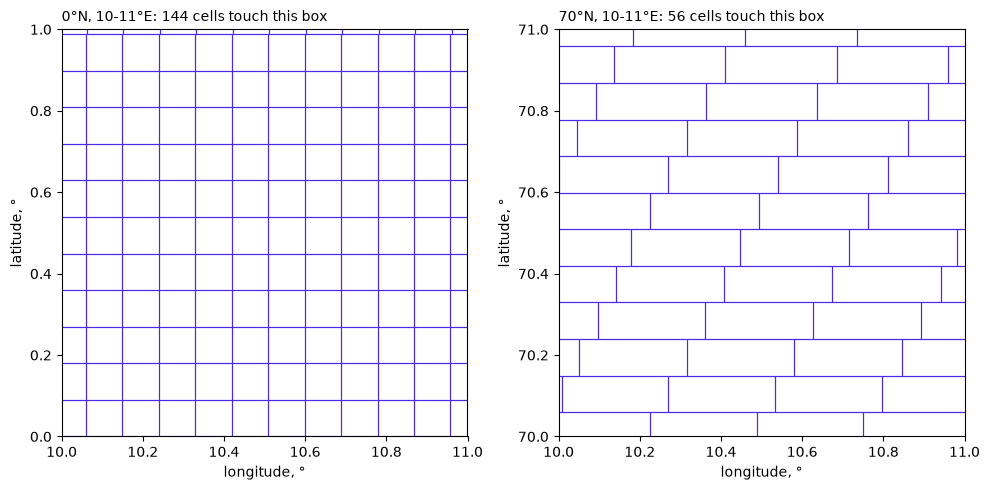

In [4]:
#@title Real cells over 1° x 1°, at the equator and at 70°N
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from majortom.cells import cells_in

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (lon, lat) in zip(axes, [(10.0, 0.0), (10.0, 70.0)]):
    box = cells_in((lon, lat, lon + 1, lat + 1))
    for r, c in zip(box.row, box.col):
        k = Cell(int(r), int(c))
        ax.add_patch(Rectangle((k.lon, k.lat), k.dlon, k.dlat, fill=False, lw=0.8, color="#492ae8"))
    ax.set_xlim(lon, lon + 1), ax.set_ylim(lat, lat + 1)
    ax.set_title(f"{lat:.0f}°N, {lon:.0f}-{lon + 1:.0f}°E: {len(box)} cells touch this box", loc="left", fontsize=10)
    ax.set_xlabel("longitude, °"), ax.set_ylabel("latitude, °")
plt.tight_layout()

## 3. Points and areas to cells

Every dataset starts from a table of cells. The functions below return one row per cell with `grid_cell`, `row`,
`col`, `grid_km`, and the cell's centroid as `lon`, `lat`.

| Function | Input | Notes |
|---|---|---|
| `cells_from_points(points, d=10)` | a table with `lon`, `lat` columns (CSV, GeoJSON points, a DataFrame) | points in the same cell become one sample; `n_points` counts them; other columns are kept from the first point; `point_lon`, `point_lat` keep the original position |
| `cells_in(area, d=10)` | a lon/lat box `(west, south, east, north)` or a shapely polygon in lon/lat | every cell that touches the area; does not cross 180° |
| `cell_from_name(name, d=10)` | a cell name | for datasets that already have `grid_cell` |

**Per-sample queries.** Three optional columns in the cells table change how `majortom.build` makes that sample:
`datetime` (an interval `"2024-06-01/2024-08-31"` or one time), `days` (search ± days around that time) and `margin`
(the window margin). Points in one cell with different queries stay separate samples.

In [5]:
import pandas as pd
from majortom import build

points = pd.DataFrame({
    "name": ["Loch Lomond", "Loch Lomond, east shore", "Dolomites", "Manaus"],
    "lon": [-4.60, -4.58, 11.87, -60.02],
    "lat": [56.10, 56.11, 46.55, -3.10],
})
cells = build.cells_from_points(points)        # the same function as majortom.cells.cells_from_points
cells[["grid_cell", "name", "n_points", "lon", "lat"]]

,grid_cell,name,n_points,lon,lat
0,624U_29L,Loch Lomond,2,-4.582403,56.092814
1,518U_90R,Dolomites,1,11.812908,46.571856
2,35D_668L,Manaus,1,-60.044978,-3.098802


In [6]:
import shapely

area = shapely.Polygon([(-5.0, 55.8), (-4.0, 55.8), (-5.0, 56.4)])     # a triangle over the Loch Lomond area
print(len(build.cells_in(area.bounds)), "cells in its bounding box,", len(build.cells_in(area)), "touch the triangle")
# from a file: geopandas.read_file("area.geojson").to_crs(4326).union_all() gives the polygon

53 cells in its bounding box, 32 touch the triangle


## 4. Build samples from public archives

`build.download(cells, collection, datetime)` makes one sample per row of `cells`: it finds the cell's window
(section 4.4 below), searches the archive, picks a scene, reads only the window, and writes the sample. The products
and their periods in each archive, generated from the installed package (`COLLECTIONS` for products, `ARCHIVES`
for archives), so it lists exactly what your version supports. New products are added by contributors (section 4.9):

In [7]:
from IPython.display import Markdown
from majortom.build import catalogue

Markdown(catalogue.table())

| Product | Kind | Bands | planetary-computer | earth-search | cdse | earthdata | earth-engine |
|---|---|---|---|---|---|---|---|
| [`aster-l1t`](https://lpdaac.usgs.gov/products/ast_l1tv003/) | optical | 14 | [2000-03 – 2006-12](https://planetarycomputer.microsoft.com/dataset/aster-l1t) | — | — | — | [2000-03 –](https://developers.google.com/earth-engine/datasets/catalog/ASTER_AST_L1T_003) |
| [`hls2-l30`](https://hls.gsfc.nasa.gov/) | optical | 10 | [2020-01 –](https://planetarycomputer.microsoft.com/dataset/hls2-l30) | — | — | [2013-04 –](https://www.earthdata.nasa.gov/data/catalog/lpcloud-hlsl30-2.0) | [2013-04 –](https://developers.google.com/earth-engine/datasets/catalog/NASA_HLS_HLSL30_v002) |
| [`hls2-s30`](https://hls.gsfc.nasa.gov/) | optical | 13 | [2020-01 –](https://planetarycomputer.microsoft.com/dataset/hls2-s30) | — | — | [2015-11 –](https://www.earthdata.nasa.gov/data/catalog/lpcloud-hlss30-2.0) | [2015-11 –](https://developers.google.com/earth-engine/datasets/catalog/NASA_HLS_HLSS30_v002) |
| [`landsat-c2-l1`](https://landsat.gsfc.nasa.gov/) | optical | 11 | — | — | — | — | [2013-03 –](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1) |
| [`landsat-c2-l2`](https://landsat.gsfc.nasa.gov/) | optical | 7 | [1982-08 –](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2) | — | — | — | [1982-08 –](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2) |
| [`modis-09a1`](https://lpdaac.usgs.gov/products/mod09a1v061/) | optical | 7 | [2000-02 –](https://planetarycomputer.microsoft.com/dataset/modis-09A1-061) | — | — | — | [2000-02 –](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MYD09A1) |
| [`modis-09q1`](https://lpdaac.usgs.gov/products/mod09q1v061/) | optical | 2 | [2000-02 –](https://planetarycomputer.microsoft.com/dataset/modis-09Q1-061) | — | — | — | [2000-02 –](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MYD09Q1) |
| [`modis-13q1`](https://lpdaac.usgs.gov/products/mod13q1v061/) | optical | 2 | [2000-02 –](https://planetarycomputer.microsoft.com/dataset/modis-13Q1-061) | — | — | — | [2000-02 –](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MYD13Q1) |
| [`modis-43a4`](https://lpdaac.usgs.gov/products/mcd43a4v061/) | optical | 7 | [2000-02 –](https://planetarycomputer.microsoft.com/dataset/modis-43A4-061) | — | — | — | [2000-02 –](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD43A4) |
| [`sentinel-2-l1c`](https://sentiwiki.copernicus.eu/web/sentinel-2) | optical | 13 | — | [2015-06 –](https://radiantearth.github.io/stac-browser/#/external/earth-search.aws.element84.com/v1/collections/sentinel-2-l1c) | [2015-06 –](https://browser.stac.dataspace.copernicus.eu/collections/sentinel-2-l1c) | — | [2015-06 –](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_HARMONIZED) |
| [`sentinel-2-l2a`](https://sentiwiki.copernicus.eu/web/sentinel-2) | optical | 12 | [2015-06 –](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a) | [2015-06 –](https://radiantearth.github.io/stac-browser/#/external/earth-search.aws.element84.com/v1/collections/sentinel-2-c1-l2a) | [2015-06 –](https://browser.stac.dataspace.copernicus.eu/collections/sentinel-2-l2a) | — | [2017-03 –](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED) |
| [`sentinel-3-olci-l1`](https://sentiwiki.copernicus.eu/web/sentinel-3) | optical | 21 | — | — | [2020-04 –](https://browser.stac.dataspace.copernicus.eu/collections/sentinel-3-olci-1-efr-ntc) | — | [2016-10 –](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S3_OLCI) |
| [`sentinel-3-olci-l2-lfr`](https://sentiwiki.copernicus.eu/web/sentinel-3) | optical | 3 | [2016-04 –](https://planetarycomputer.microsoft.com/dataset/sentinel-3-olci-lfr-l2-netcdf) | — | [2016-04 –](https://browser.stac.dataspace.copernicus.eu/collections/sentinel-3-olci-2-lfr-ntc) | — | — |
| [`alos-palsar-mosaic`](https://www.eorc.jaxa.jp/ALOS/en/palsar_fnf/fnf_index.htm) | radar | 2 | [2015-01 – 2021-12](https://planetarycomputer.microsoft.com/dataset/alos-palsar-mosaic) | — | — | — | — |
| [`opera-rtc-s1`](https://www.earthdata.nasa.gov/data/projects/opera) | radar | 2 | — | — | — | [2016-04 –](https://www.earthdata.nasa.gov/data/catalog/asf-opera-l2-rtc-s1-v1-1) | — |
| [`sentinel-1-grd`](https://sentiwiki.copernicus.eu/web/sentinel-1) | radar | 2 | [2014-10 –](https://planetarycomputer.microsoft.com/dataset/sentinel-1-grd) | [2014-10 –](https://radiantearth.github.io/stac-browser/#/external/earth-search.aws.element84.com/v1/collections/sentinel-1-grd) | [2014-10 –](https://browser.stac.dataspace.copernicus.eu/collections/sentinel-1-grd) | — | — |
| [`sentinel-1-grd-tc`](https://sentiwiki.copernicus.eu/web/sentinel-1) | radar | 2 | — | — | — | — | [2014-10 –](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD) |
| [`sentinel-1-rtc`](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc) | radar | 2 | [2014-10 –](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc) | — | — | — | — |
| [`alos-dem`](https://www.eorc.jaxa.jp/ALOS/en/dataset/aw3d30/aw3d30_e.htm) | elevation | 1 | [static](https://planetarycomputer.microsoft.com/dataset/alos-dem) | — | — | — | — |
| [`cop-dem-glo-30`](https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-description/COP-DEM) | elevation | 1 | [static](https://planetarycomputer.microsoft.com/dataset/cop-dem-glo-30) | [static](https://radiantearth.github.io/stac-browser/#/external/earth-search.aws.element84.com/v1/collections/cop-dem-glo-30) | [static](https://browser.stac.dataspace.copernicus.eu/collections/cop-dem-glo-30-dged-cog) | — | — |
| [`nasadem`](https://lpdaac.usgs.gov/products/nasadem_hgtv001/) | elevation | 1 | [static](https://planetarycomputer.microsoft.com/dataset/nasadem) | — | — | — | — |
| [`alos-fnf-mosaic`](https://www.eorc.jaxa.jp/ALOS/en/palsar_fnf/fnf_index.htm) | land cover | 1 | [2015-01 – 2020-12](https://planetarycomputer.microsoft.com/dataset/alos-fnf-mosaic) | — | — | — | — |
| [`dynamic-world`](https://dynamicworld.app/) | land cover | 10 | — | — | — | — | [2015-06 –](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1) |
| [`esa-cci-lc`](https://climate.esa.int/en/projects/land-cover/) | land cover | 5 | [1992-01 – 2020-12](https://planetarycomputer.microsoft.com/dataset/esa-cci-lc) | — | — | — | — |
| [`esa-worldcover`](https://esa-worldcover.org/) | land cover | 2 | [2020-01 – 2021-12](https://planetarycomputer.microsoft.com/dataset/esa-worldcover) | — | — | — | — |
| [`io-lulc-annual-v02`](https://www.impactobservatory.com/) | land cover | 1 | [2017-01 – 2024-01](https://planetarycomputer.microsoft.com/dataset/io-lulc-annual-v02) | — | — | — | — |
| [`opera-dist-alert-hls`](https://www.earthdata.nasa.gov/data/projects/opera) | land cover | 3 | — | — | — | [2023-01 –](https://www.earthdata.nasa.gov/data/catalog/lpcloud-opera-l3-dist-alert-hls-v1-1) | — |
| [`modis-11a2`](https://lpdaac.usgs.gov/products/mod11a2v061/) | temperature | 2 | [2000-02 –](https://planetarycomputer.microsoft.com/dataset/modis-11A2-061) | — | — | — | [2000-02 –](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MYD11A2) |
| [`viirs-dnb-monthly`](https://eogdata.mines.edu/products/vnl/) | night lights | 2 | — | — | — | — | [2014-01 –](https://developers.google.com/earth-engine/datasets/catalog/NOAA_VIIRS_DNB_MONTHLY_V1_VCMSLCFG) |
| [`hgb`](https://daac.ornl.gov/cgi-bin/dsviewer.pl?ds_id=1763) | biomass | 4 | [static](https://planetarycomputer.microsoft.com/dataset/hgb) | — | — | — | — |
| [`jrc-gsw`](https://global-surface-water.appspot.com/) | water | 6 | [static](https://planetarycomputer.microsoft.com/dataset/jrc-gsw) | — | — | — | — |
| [`opera-dswx-hls`](https://www.earthdata.nasa.gov/data/projects/opera) | water | 3 | — | — | — | [2016-01 –](https://www.earthdata.nasa.gov/data/catalog/pocloud-opera-l3-dswx-hls-v1-1.0) | — |
| [`opera-dswx-s1`](https://www.earthdata.nasa.gov/data/projects/opera) | water | 3 | — | — | — | [2023-12 –](https://www.earthdata.nasa.gov/data/catalog/pocloud-opera-l3-dswx-s1-v1-1.0) | — |

### 4.1 Archives

The archives at the time of writing (current list: `majortom.build.archives.ARCHIVES`):

| `archive` | Account | Notes |
|---|---|---|
| `planetary-computer` | none | the default; most products |
| `earth-search` | none | Sentinel-2 L1C; Collection 1 reprocessed L2A |
| `cdse` | Copernicus Data Space S3 keys | ESA's own archive, as the Core datasets were built from |
| `earthdata` | NASA Earthdata token | HLS before 2020, OPERA products |
| `earth-engine` | a registered Google Cloud project | Landsat L1, MODIS, Dynamic World, Sentinel-1 GRD, VIIRS, Sentinel-3 OLCI; uses the project's quota |

Credentials are set up once: `python -m majortom.build.credentials <cdse | earthdata | earth-engine>` asks for them
with hidden input and stores them in owner-only files (or set the environment variables it names). Asking for dates
outside a product's period, or a product an archive does not have, raises an error naming the archives that have it.
Details: [ARCHIVES.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/ARCHIVES.md).

<img src="https://raw.githubusercontent.com/ESA-PhiLab/Major-TOM/refactor/v1/docs/animations/out/archives_matrix.png" alt="What each archive offers and asks for" width="720">

### 4.2 When

| Argument | Meaning |
|---|---|
| `datetime` | `"start/end"` or one time. Yearly products (land cover, mosaics): selects the version, e.g. `"2021"`. Static products (DEMs): ignored |
| `days` | widen a single `datetime` by ± days |
| columns `datetime`, `days` in `cells` | override both for that sample |

### 4.3 Which scene

Up to five scenes are tried per sample, in the order of `prefer`; the first that meets `cloud` and `max_nodata`
is used.

| Argument | Values |
|---|---|
| `prefer` | `"clearest"` (default), `"cloudiest"`, `"nearest"` (to the date), `"newest"` |
| `cloud` | accepted share of cloudy pixels in the window, `(low, high)`: `(0, 0.05)` (default) for clear samples, `(0.3, 1)` for cloudy ones, `None` for any |
| `max_nodata` | accepted share of window pixels without data (default `0.01`) |
| `strict` | `True`: a sample with no acceptable scene fails. `False` (default): the best scene tried is used |
| `fallback` | the best when none is acceptable: `"complete"` (default; least missing data, then clouds) or `"clear"` |
| `platform` | only these satellites, e.g. `"terra"`, `["landsat-8", "landsat-9"]` |

Clouds are measured in the window itself (from the product's own mask where it has one); the sample records the
share and how it was measured.

### 4.4 Which window

| `window` | Window |
|---|---|
| `"v2"` (default) | centred on the cell, 10,560 m (1056 px at 10 m), on a 60 m lattice in the cell's UTM zone ([SPEC section 3](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/SPEC.md)) |
| `"v1"` | the Core datasets' window, 10,680 m (1068 px), so new samples line up pixel for pixel with Core samples |

`margin` sets the v2 window's margin as a fraction of `d` (default 0.056). Each source keeps its own pixel size:
a 10 m and a 30 m product cover the same window.

### 4.5 Running and output

| Argument | Meaning |
|---|---|
| `outdir` | where samples go (default `chips`) |
| `workers` | parallel samples; default: what the archive allows |
| `force` | `True`: rebuild everything. Default: reuse a sample built for the same request; remove samples of rows no longer in `cells` |

Each sample is `<outdir>/<collection>/<index>.npz` (one array per band) and a `.json` sidecar: cell, window, CRS,
resolution, source items, archive, date, cloud share and source, no-data share, scaling and offsets, and timing.
`download` returns the samples that failed, with the reason.

### 4.6 Every product that needs no account, at one cell

Every product the installed package knows (`COLLECTIONS`) that is on Planetary Computer or Earth Search, built for
Loch Lomond (624U_29L). Each product carries its own `example` dates (with data at this cell) and `preview` (how to
show it), so products added to the package appear here without changes to this notebook. This takes about ten
minutes.

In [8]:
import json
from pathlib import Path

import numpy as np
from majortom.build.collections import COLLECTIONS

FREE = ("planetary-computer", "earth-search")
loch = build.cells_from_points(pd.DataFrame({"lon": [-4.58], "lat": [56.09]}))
built, needs_account = {}, {}
for name, collection in COLLECTIONS.items():
    archive = next((a for a in FREE if a in collection.archives()), None)
    if archive is None:
        needs_account[name] = collection.archives()
        continue
    failed = build.download(loch, name, collection.example, archive=archive, outdir=f"products/{archive}", max_nodata=0.05)
    built[name] = archive if failed.empty else f"failed: {failed.iloc[0]['error']}"
ok = [n for n, a in built.items() if not a.startswith("failed")]
print(len(ok), "of", len(built), "products that need no account built at 624U_29L")
for name, result in built.items():
    if result.startswith("failed"):
        print(f"  {name} ({next(a for a in FREE if a in COLLECTIONS[name].archives())}): {result}")
print(len(needs_account), "products need an account:")
for name, archives in needs_account.items():
    print(f"  {name}: {', '.join(archives)}")

sentinel-2-l2a:   0%|          | 0/1 [00:00<?, ?it/s]

sentinel-2-l2a: 100%|██████████| 1/1 [00:15<00:00, 15.94s/it]

sentinel-2-l2a: 100%|██████████| 1/1 [00:15<00:00, 15.95s/it]

1 samples in products/planetary-computer/sentinel-2-l2a, 0 failed


sentinel-2-l1c:   0%|          | 0/1 [00:00<?, ?it/s]

sentinel-2-l1c: 100%|██████████| 1/1 [00:57<00:00, 57.58s/it]

... (85 outputs left out)

jrc-gsw:   0%|          | 0/1 [00:00<?, ?it/s]

jrc-gsw: 100%|██████████| 1/1 [00:01<00:00,  1.60s/it]

jrc-gsw: 100%|██████████| 1/1 [00:01<00:00,  1.61s/it]

1 samples in products/planetary-computer/jrc-gsw, 0 failed
23 of 24 products that need no account built at 624U_29L
  modis-09q1 (planetary-computer): failed: LookupError: no scene found (dates 2024-06-01/2024-08-31)
9 products need an account:
  landsat-c2-l1: earth-engine
  dynamic-world: earth-engine
  viirs-dnb-monthly: earth-engine
  sentinel-3-olci-l1: cdse, earth-engine
  sentinel-1-grd-tc: earth-engine
  opera-rtc-s1: earthdata
  opera-dswx-hls: earthdata
  opera-dswx-s1: earthdata
  opera-dist-alert-hls: earthdata


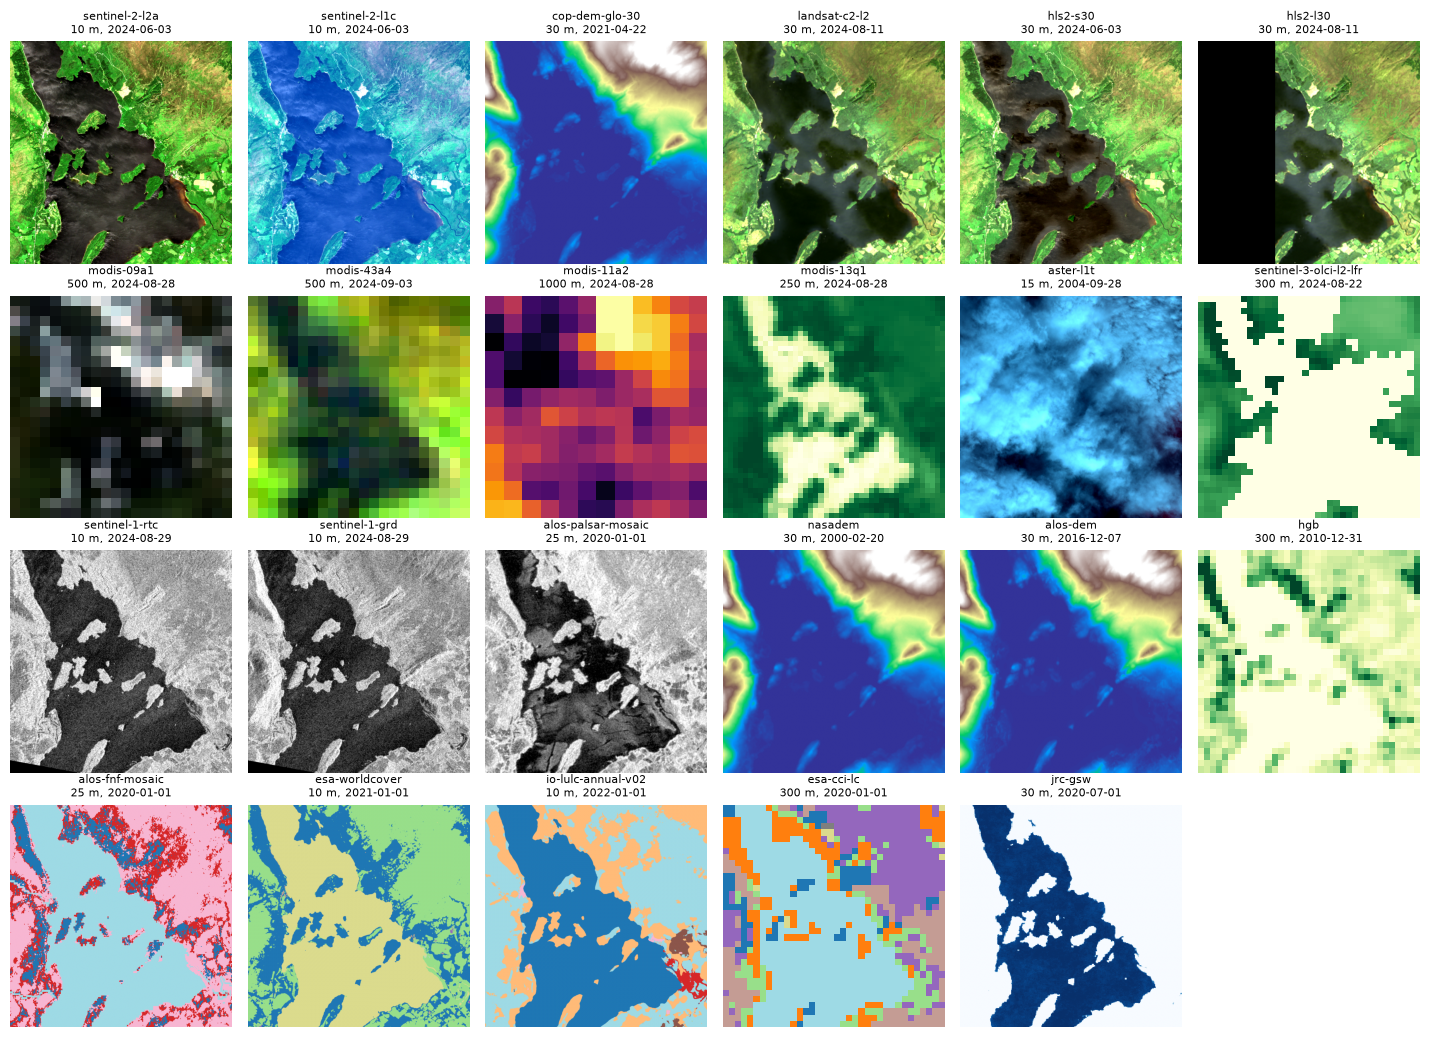

In [9]:
#@title Every product at 624U_29L
def preview(name, side, a):
    """An image to show, from the product's Preview: RGB, one band with a colour map, or classes."""
    view = COLLECTIONS[name].preview
    band = lambda b: a[next(k for k in a.files if k == b or k.startswith(f"{b}_"))].astype(float)
    if view.classes:                                             # one colour per class present
        values = band(view.classes)
        return np.unique(values, return_inverse=True)[1].reshape(values.shape), "tab20"
    if view.rgb and all(b in side["bands"] for b in view.rgb):
        v, cmap = np.dstack([band(b) for b in view.rgb]), None
    else:
        v, cmap = band(view.band or side["bands"][0]), view.cmap
    if view.db == "power":                                       # radar backscatter in dB
        v = 10 * np.log10(np.clip(v, 1e-5, None))
    elif view.db == "amplitude":
        v = 20 * np.log10(np.clip(v, 1, None))
    elif view.db == "palsar":
        v = 10 * np.log10(np.clip(v, 1, None) ** 2) - 83
    lo, hi = np.nanpercentile(v, (2, 98))
    return np.clip((v - lo) / (hi - lo + 1e-12), 0, 1), cmap

names = [n for n, archive in built.items() if not archive.startswith("failed")]
ncol = 6
fig, axes = plt.subplots(-(-len(names) // ncol), ncol, figsize=(2.4 * ncol, 2.6 * -(-len(names) // ncol)), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, name in zip(axes.flat, names):
    stem = Path(f"products/{built[name]}/{name}/000000")
    side = json.loads(stem.with_suffix(".json").read_text())
    img, cmap = preview(name, side, np.load(stem.with_suffix(".npz")))
    ax.imshow(img, cmap=cmap)
    when = side["datetime"][:10] if side.get("datetime") else "static"
    ax.set_title(f"{name}\n{side['res']:g} m, {when}", fontsize=8)
plt.tight_layout()

### 4.7 Several cells, several sources

The same call for any table of cells: here four products for the three cells of section 3.

In [10]:
SOURCES = {                                   # collection -> dates
    "sentinel-2-l2a": "2024-06-01/2024-08-31",
    "sentinel-1-rtc": "2024-06-01/2024-08-31",
    "cop-dem-glo-30": None,                   # static
    "esa-worldcover": "2021",                 # yearly: the 2021 version
}
for collection, dates in SOURCES.items():
    failed = build.download(cells, collection, dates)
    print(f"{collection}: {len(cells) - len(failed)} built, {len(failed)} failed")

sentinel-2-l2a:   0%|          | 0/3 [00:00<?, ?it/s]

sentinel-2-l2a:  33%|███▎      | 1/3 [00:00<00:01,  1.11it/s]

sentinel-2-l2a:  67%|██████▋   | 2/3 [00:17<00:09,  9.96s/it]

sentinel-2-l2a: 100%|██████████| 3/3 [00:17<00:00,  5.71s/it]

sentinel-2-l2a: 100%|██████████| 3/3 [00:17<00:00,  5.95s/it]

3 samples in chips/sentinel-2-l2a, 0 failed
sentinel-2-l2a: 3 built, 0 failed


... (14 outputs left out)

esa-worldcover:  67%|██████▋   | 2/3 [00:00<00:00,  2.53it/s]

esa-worldcover: 100%|██████████| 3/3 [00:01<00:00,  2.21it/s]

esa-worldcover: 100%|██████████| 3/3 [00:01<00:00,  2.28it/s]

3 samples in chips/esa-worldcover, 0 failed
esa-worldcover: 3 built, 0 failed


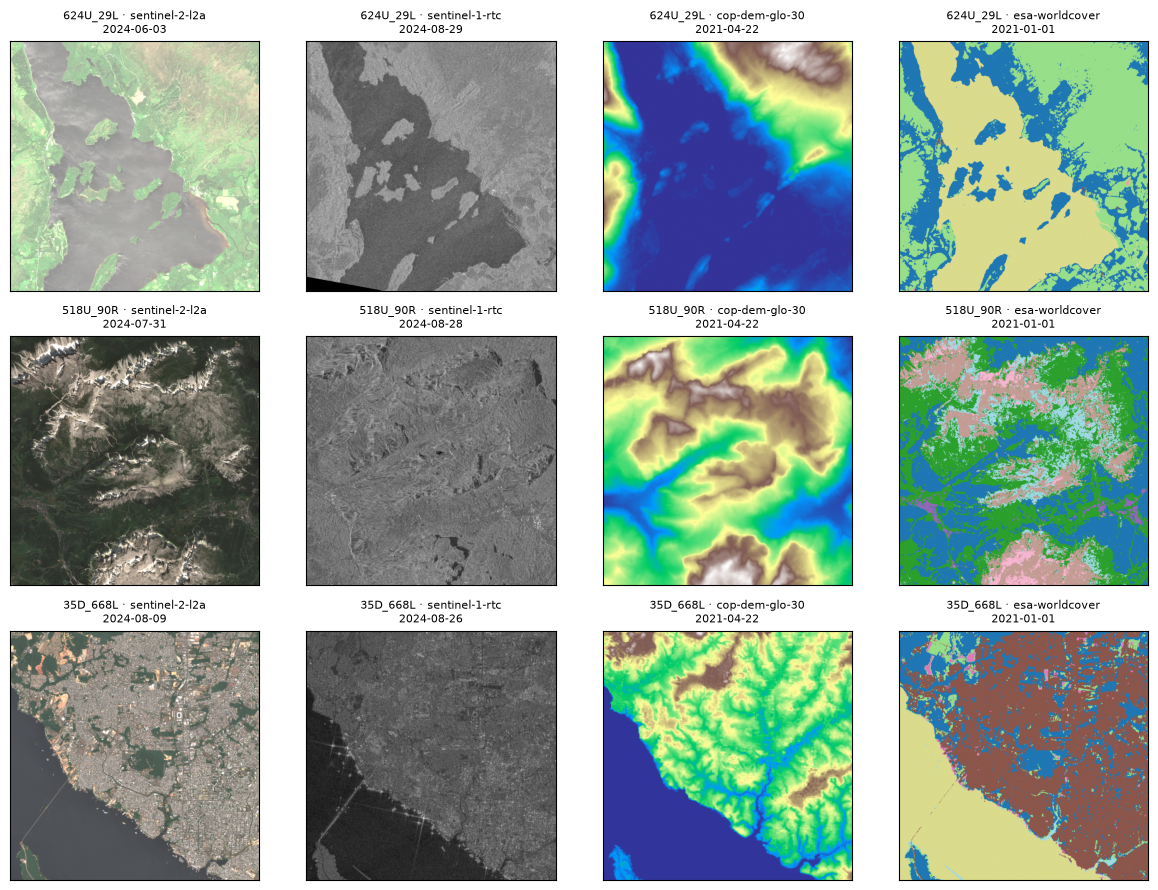

In [11]:
#@title One row per cell, one column per source (all the same window)
import json
from pathlib import Path
import numpy as np

def show(collection, a):
    if collection == "sentinel-2-l2a":
        rgb = np.stack([a["B04"], a["B03"], a["B02"]], -1).astype(float)
        return np.clip(rgb / np.percentile(rgb, 99), 0, 1), None
    if collection == "sentinel-1-rtc":
        return 10 * np.log10(np.maximum(a["vv"], 1e-4)), "gray"
    if collection == "cop-dem-glo-30":
        return a["DEM"], "terrain"
    return a["map"], "tab20"

fig, axes = plt.subplots(len(cells), len(SOURCES), figsize=(3 * len(SOURCES), 3 * len(cells)), squeeze=False)
for col, collection in enumerate(SOURCES):
    for row in range(len(cells)):
        side = json.loads(Path(f"chips/{collection}/{row:06d}.json").read_text())
        img, cmap = show(collection, np.load(f"chips/{collection}/{row:06d}.npz"))
        ax = axes[row, col]
        ax.imshow(img, cmap=cmap), ax.set_xticks([]), ax.set_yticks([])
        ax.set_title(f"{side['grid_cell']} · {collection}\n{side['datetime'][:10] if side.get('datetime') else 'static'}", fontsize=8)
plt.tight_layout()

### 4.8 Archives compared

**Values.** Where two archives hold the same processing of an acquisition, samples are identical pixel for pixel
once each sample's recorded `offset` is removed: Sentinel-2 L2A (Earth Search, CDSE, Planetary Computer, Earth
Engine), Landsat L2 (Earth Engine, Planetary Computer), HLS (Earthdata, Planetary Computer), Copernicus DEM (all
three archives that have it). Where processing versions differ (e.g. Planetary Computer's Sentinel-2 originals
against reprocessed Collection 1), values differ by up to a few hundred stored units; every sample records its
`processing_baseline`. ([ARCHIVES.md section 5](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/ARCHIVES.md))

**Speed.** Measured on 2026-10-22 from a server in the UK, 8 cells around Loch Lomond per product and archive
([report](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/reports/2026-10-22-build-speed.md)). Sentinel-2 L2A, samples per hour at each archive's default
workers:

| Archive | Workers | Samples/hour | Seconds per sample |
|---|--:|--:|--:|
| planetary-computer | 16 | 1,177 | 18.2 |
| earth-search | 16 | 384 | 72.7 |
| earth-engine | 8 | 215 | 31.6 |
| cdse | 4 | 207 | 69.2 |

Every sample records its own `timing` (search, scene choice, each band).

The same cell from Earth Search, against the Planetary Computer sample above:

In [12]:
failed = build.download(cells.iloc[:1], "sentinel-2-l2a", SOURCES["sentinel-2-l2a"], archive="earth-search",
                        outdir="chips-earth-search")
a, b = (json.loads(Path(f"{d}/sentinel-2-l2a/000000.json").read_text()) for d in ("chips", "chips-earth-search"))
print("Planetary Computer:", a["items"][0], "|", a["source_collection"], a["processing_baseline"])
print("Earth Search:      ", b["items"][0], "|", b["source_collection"], b["processing_baseline"])
import re
scene = lambda side: (re.search(r"T\d{2}[A-Z]{3}", side["items"][0]).group(), re.search(r"\d{8}T\d{6}", side["items"][0]).group())
if scene(a) == scene(b):                                         # same tile and datatake (archives record times differently)
    x, y = ((np.load(f"{d}/sentinel-2-l2a/000000.npz")["B04"].astype(int) - s["offset"]["B04"])
            for d, s in (("chips", a), ("chips-earth-search", b)))
    d = x - y
    print("same scene", scene(a), "and window; B04 difference once offsets are removed: median", np.median(d),
          "| 5th-95th percentile", np.percentile(d, [5, 95]), "| correlation", round(np.corrcoef(x.ravel(), y.ravel())[0, 1], 5))
    if a["source_collection"] != b["source_collection"]:
        print("different processings of this scene (the archives' collections differ), so small differences are expected")
else:
    print("different scenes were chosen:", scene(a), scene(b))

sentinel-2-l2a:   0%|          | 0/1 [00:00<?, ?it/s]

sentinel-2-l2a: 100%|██████████| 1/1 [00:55<00:00, 55.23s/it]

sentinel-2-l2a: 100%|██████████| 1/1 [00:55<00:00, 55.23s/it]

1 samples in chips-earth-search/sentinel-2-l2a, 0 failed
Planetary Computer: S2A_MSIL2A_20240603T114351_R123_T30VUH_20240603T182051 | sentinel-2-l2a 05.10
Earth Search:       S2A_T30VUH_20240603T114351_L2A | sentinel-2-c1-l2a 05.10
same scene ('T30VUH', '20240603T114351') and window; B04 difference once offsets are removed: median 4.0 | 5th-95th percentile [-4.  7.] | correlation 0.99958
different processings of this scene (the archives' collections differ), so small differences are expected


### 4.9 Adding a product or an archive

A product is one `Collection` entry in `majortom/build/collections.py` (its bands, kind, period, and one `Source`
per archive with that archive's names); an archive reachable by STAC and GDAL is one `Archive` entry in
`archives.py`. Each needs test dates in `tests/test_products.py`. Steps and checks:
[CONTRIBUTING.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/CONTRIBUTING.md).

## 5. Release as a TACO dataset

`majortom.release.release(samples, out, ...)` turns the built samples of one product into a
[TACO](https://pypi.org/project/taco-eo/) dataset: a catalogue of samples with their metadata, and the image files.
Design and benchmarks: [RELEASE.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/RELEASE.md).

**What it does with each sample:** bands with the same pixel size are stored together, one file per group
(Sentinel-2: `10m`, `20m`, `60m`); samples are ordered along a Hilbert curve over the globe, so neighbouring cells are
stored together; the dataset is cut into ZIP partitions with a `.tacocat` catalogue beside them; sample ids are
`MT10km_<row>_<col>_<time>` (e.g. `MT10km_0624U_0029L_20240603T114351`).

| Argument | Meaning |
|---|---|
| `samples` | the `.npz` files of one product (all with the same raster groups) |
| `out` | a `.zip` path (partitions and the `.tacocat` beside it) or a folder |
| `id`, `title`, `description`, `licenses`, `providers`, `keywords` | the dataset's catalogue entry |
| `profile` | the rumi compression: `"lossless"` (default), `"near-lossless-1"`, `"near-lossless-2"` (every pixel within 1 or 2 units) |
| `max_bytes` | partition size limit, default 3 GB |
| `with_time` | `False` for one sample per cell (e.g. a DEM): ids are the cell alone |
| `stats` | per-file band statistics in the catalogue (default `True`) |
| `geoenrich` | context per sample from taco-eo's GeoEnrich (country, region, elevation, climate, population, ...): `True` (default), a list of names, or `False`; skipped with a warning when offline |
| `stage`, `overwrite` | the working folder; replace an existing dataset |

**Payload.** Files are [rumi](https://pypi.org/project/rumi-eo/) (lossless by default: 19% smaller than COG and 1.8x
faster for training crops in our benchmark). `majortom.release.read(location, header, as_="cog")` gives any file as a
Cloud Optimized GeoTIFF, and `python -m majortom.release to-cog` converts a whole dataset or a selection.

**Command line:** `python -m majortom.release build --samples <folder> --out <out.zip> --id <id> --description <text>`.

In [13]:
from majortom.release import release

samples = sorted(Path("chips/sentinel-2-l2a").glob("*.npz"))
dataset_path = release(samples, "release/my-sentinel-2.zip", id="my-sentinel-2",
                       description="Sentinel-2 L2A samples on the Major TOM grid, built with majortom.build.",
                       licenses=["CC-BY-4.0"], providers=["Your Name"], overwrite=True)
print(dataset_path.relative_to(Path.cwd()), "|", sorted(f.name for f in Path("release").iterdir()))

release/.tacocat | ['.tacocat', 'my-sentinel-2.zip']


### 5.1 Query and read it

`taco.open_dataset` opens a local folder or a URL; `sql` runs DuckDB SQL over the catalogue (`dataset` has one row
per file, `sample` one per sample). `<group>.rumi::location` and `::header` point at each file.

In [14]:
import taco
from majortom.release import read

dataset = taco.open_dataset("release")
table = dataset.sql('SELECT id, "10m.rumi::location" AS location, "10m.rumi::header" AS header FROM dataset').to_pandas()
print(table.id.to_string(index=False))
ten = read(table.location[0], table.header[0])                     # the 10 m group: (bands, y, x)
print("10 m group of", table.id[0], ten.shape, ten.dtype)

MT10km_0035D_0668L_20240809T141719
MT10km_0624U_0029L_20240603T114351
MT10km_0518U_0090R_20240731T100559
10 m group of MT10km_0035D_0668L_20240809T141719 (4, 1056, 1056) uint16


In [15]:
cog = read(table.location[0], table.header[0], as_="cog")          # the same file as an in-memory COG
with cog, cog.open() as src:
    print(src.profile["driver"], src.crs, src.res, src.count, "bands", src.block_shapes[0], "blocks")

GTiff EPSG:32720 (10.0, 10.0) 4 bands (176, 176) blocks


### 5.2 A published release

`major-tom/release-test` on source.coop holds one TACO dataset per source, each built with `majortom.build` at
three cells and released with `majortom.release`. It opens from its URL like the local one: only the catalogue and
the bytes of the files read are fetched. `majortom:code` is each sample's cell.

In [16]:
url = "https://data.source.coop/major-tom/release-test/sentinel-1-rtc/"
remote = taco.open_dataset(url)
rows = remote.sql('SELECT id, "majortom:code" AS cell, "10m.rumi::location" AS location, "10m.rumi::header" AS header FROM dataset').to_pandas()
print(rows[["id", "cell"]].to_string(index=False))
vv = read(rows.location[0], rows.header[0])
print("10 m group of", rows.id[0], vv.shape, vv.dtype)

                                id               cell
MT10km_0035D_0667L_20230609T093947 MT10km_0035D_0667L
MT10km_0035D_0667L_20230925T093953 MT10km_0035D_0667L
MT10km_0624U_0029L_20230629T063848 MT10km_0624U_0029L
MT10km_0624U_0029L_20230928T063039 MT10km_0624U_0029L
MT10km_0518U_0090R_20230628T170733 MT10km_0518U_0090R
MT10km_0518U_0090R_20230927T165921 MT10km_0518U_0090R


10 m group of MT10km_0035D_0667L_20230609T093947 (2, 1056, 1056) float32


### 5.3 A subset of a published dataset

`taco.export(source, out, sql=...)` copies the samples selected by SQL into a new TACO dataset: it queries the
catalogue first, then fetches only the selected files. Here, from the TACO version of Core-DEM on source.coop (`major-tom/core-dem`):
the least modified cell above 4,000 m in each region of Peru, using the GeoEnrich attributes.

In [17]:
QUERY = """
    SELECT * FROM sample
    WHERE "geoenrich:admin_countries" = 'Peru' AND "geoenrich:elevation" > 4000 AND "geoenrich:human_modification" < 0.05
    QUALIFY row_number() OVER (PARTITION BY "geoenrich:admin_states"
                               ORDER BY "geoenrich:human_modification", "geoenrich:elevation" DESC) = 1
"""
subset = taco.export("https://data.source.coop/major-tom/core-dem", "release/core-dem-peru.zip", sql=QUERY,
                     overwrite=True, id="core-dem-peru", description="Least modified Core-DEM cell above 4,000 m per Peruvian region.")
print(subset.samples, "samples,", round(subset.size / 1e6, 1), "MB")
print("validation issues:", len(taco.validate(subset.path).issues))

15 samples, 0.7 MB
validation issues: 0


## 6. Publish

`majortom.release.publish.publish(folder, destination)` uploads a release folder. It is resumable (files already
there with the same size and checksum are skipped) and checks every file after uploading.

| Destination | Form | Credentials |
|---|---|---|
| source.coop | `"source.coop://<account>/<repository>[/<prefix>]"` | a repository API key: `python -m majortom.build.credentials source-coop` |
| Hugging Face | `"hf://<user or organisation>/<dataset repository>"` | `huggingface-cli login` or `HF_TOKEN` |

| Argument | Meaning |
|---|---|
| `dry_run` | only list what would be uploaded |
| `include` | glob patterns of other files to upload, e.g. `["README.md", "figures/*.png"]` |
| `workers` | parallel uploads |
| `force` | upload files that are already there |

This notebook does not publish. The calls are:

```python
from majortom.release.publish import publish

report = publish("release", "source.coop://my-account/my-sentinel-2", dry_run=True)   # plan first
report = publish("release", "source.coop://my-account/my-sentinel-2")
report = publish("release", "hf://my-user/my-sentinel-2")
print(report.uploaded, report.skipped, report.verified)
```

Command line: `python -m majortom.release publish --folder release --to source.coop://my-account/my-sentinel-2`.
Once published, the dataset opens from its URL: `taco.open_dataset("https://data.source.coop/my-account/my-sentinel-2")`.

## 7. Weather and climate for the same cells

`majortom.climate` turns global weather and climate sources into values per cell (area-weighted means over each
10 km cell). Its outputs are published, so any dataset on the grid can join them on `grid_cell`:

| Dataset | Content | Where |
|---|---|---|
| CPC-Monthly | NOAA CPC gauge precipitation and temperature, 1979 to 2025 | `major-tom/climate` |
| IMERG-Monthly | GPM IMERG precipitation, from 1998 | `major-tom/climate` |
| CAMS-Monthly | CAMS reanalysis air quality, 2003 to 2025 | `major-tom/climate` |
| ERA5-Monthly | ERA5, 202 variables, 1940 to 2025 | `major-tom/climate` |
| ERA5Land-Monthly | ERA5-Land, 49 variables, 1950 to 2025 | `major-tom/climate` |
| ERA5-Static | 16 static ERA5 fields (land-sea mask, orography, soil and vegetation types, ...) | `major-tom/climate` |
| Core-Weather | hourly (±24 h) and daily (±30 days) weather and air quality around every Core-S2L2A, S2L1C and S1RTC acquisition | `major-tom/core-weather` |

Every monthly dataset has the same layout:

| Path | One row per | Use |
|---|---|---|
| `series/year=YYYY/MM.parquet` | cell, one month | a month over the globe |
| `climatology/band=NN.parquet` | cell and calendar month (1991-2020 normals: `_mean`, `_std`) | a place's normals |
| `by_cell/band=NN.parquet` | cell and month, each cell's months together | one place's whole series |
| `overviews/year=YYYY/MM.parquet` | block of 4 x 4 cells | a globe-wide map from one small file |

Files are split into 20 bands of grid rows: `band = (row + 1002) * 20 // 2004`. Filter on `grid_row_u` and
`grid_col_r`: each file has row-group statistics on them, so a reader fetches only the parts that hold your cells.

Building your own (needs `majortom[climate]` and, for some sources, credentials):
`python -m majortom.climate monthly | climatology | static | stream | merge` ([climate README](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/majortom/climate/README.md)).

In [18]:
import fsspec

https = fsspec.filesystem("https")
CLIMATE = "https://data.source.coop/major-tom/climate"
normals = []
for name, r, c in zip(cells.name, cells.row, cells.col):
    band = (int(r) + 1002) * 20 // 2004
    here = [("grid_row_u", "=", int(r)), ("grid_col_r", "=", int(c))]
    t = pd.read_parquet(f"{CLIMATE}/CPC-Monthly/climatology/band={band:02d}.parquet", filesystem=https, filters=here)
    normals.append(t.assign(name=name))
normals = pd.concat(normals)
normals.pivot(index="month", columns="name", values="cpc_precip_mean").round(2)

name,Dolomites,Loch Lomond,Manaus
month,,,
1,26.469999,122.889999,263.130005
2,22.350000,96.370003,246.889999
3,33.389999,90.360001,294.290009
4,48.950001,69.320000,269.730011
5,72.820000,66.809998,208.029999
6,93.629997,69.550003,112.279999
7,104.349998,78.629997,75.150002
8,103.160004,90.180000,57.020000
9,74.309998,85.120003,79.110001


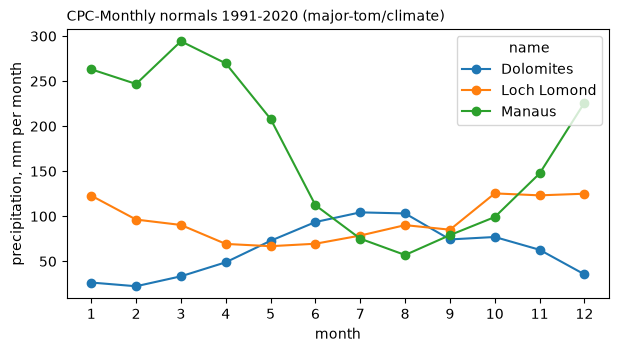

In [19]:
#@title Normal monthly precipitation per cell (NOAA CPC, 1991-2020)
ax = normals.pivot(index="month", columns="name", values="cpc_precip_mean").plot(figsize=(7, 3.5), marker="o")
ax.set_xlabel("month"), ax.set_ylabel("precipitation, mm per month"), ax.set_xticks(range(1, 13))
ax.set_title("CPC-Monthly normals 1991-2020 (major-tom/climate)", loc="left", fontsize=10);

## 8. The Core datasets

Major TOM Core is the first set of datasets on the grid, on Hugging Face:

| Dataset | Content | Samples |
|---|---|--:|
| [Core-S2L2A](https://huggingface.co/datasets/Major-TOM/Core-S2L2A) | Sentinel-2 L2A | 2,245,886 |
| [Core-S2L1C](https://huggingface.co/datasets/Major-TOM/Core-S2L1C) | Sentinel-2 L1C | 2,245,886 |
| [Core-S1RTC](https://huggingface.co/datasets/Major-TOM/Core-S1RTC) | Sentinel-1 RTC | 1,469,955 |
| [Core-DEM](https://huggingface.co/datasets/Major-TOM/Core-DEM) | Copernicus DEM 30 | 1,837,843 |
| [Core-VIIRS-Nighttime-Light](https://huggingface.co/datasets/Major-TOM/Core-VIIRS-Nighttime-Light) | VIIRS annual median night-time radiance (nW/cm²/sr), 2016-2024, 1,056 px at 10 m | 2,108,341 |
| [Core-Weather](https://source.coop/major-tom/core-weather) (source.coop) | weather and air quality, hourly for ±24 h and daily for ±30 days, around each Core-S2L2A, S2L1C and S1RTC acquisition | 3,704,013 acquisitions |

Embeddings of them: Core-S2L1C-SSL4EO, Core-S1RTC-SSL4EO, Core-S2RGB-DINOv2, Core-S2RGB-SigLIP. Every dataset of the
organisation: [huggingface.co/Major-TOM](https://huggingface.co/Major-TOM).

| Function | Does |
|---|---|
| `read_row(row, columns, georef=False)` | one sample's bands over https (only its row group); `georef=True` adds the transform and CRS |
| `filter_metadata(gdf, region, daterange, cloud_cover, nodata)` | filters the metadata table |
| `filter_download(df, local_dir, source_name)` | writes selected samples as GeoTIFF and PNG files |

Each dataset's `metadata.parquet` has one row per sample. Filter it on `grid_row_u` and `grid_col_r` (a filter on
`grid_cell` reads the whole file). Core used a 10,680 m window; readers correct its stored georeferencing by default
([SPEC section 7](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/SPEC.md)). Reading the metadata takes one to two minutes.

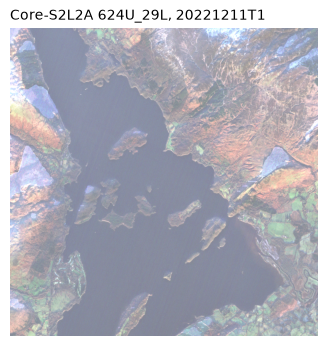

In [20]:
from majortom import read_row

url = "https://huggingface.co/datasets/Major-TOM/Core-S2L2A/resolve/main/metadata.parquet"
first = cells.iloc[0]
meta = pd.read_parquet(url, filesystem=https, filters=[("grid_row_u", "=", int(first.row)), ("grid_col_r", "=", int(first.col))])
core = read_row(meta.iloc[0], columns=["B04", "B03", "B02"])
rgb = np.stack([core[b] for b in ("B04", "B03", "B02")], -1).astype(float)
plt.figure(figsize=(4, 4)), plt.imshow(np.clip(rgb / np.percentile(rgb, 99), 0, 1)), plt.axis("off")
plt.title(f"Core-S2L2A {first.grid_cell}, {meta.iloc[0].timestamp[:10]}", loc="left", fontsize=10);

Core-VIIRS-Nighttime-Light stores each tile as a GeoTIFF inside zip shards (cozip). `INDEX.parquet`, one row per
tile, gives the tile's shard and byte range, so one HTTP range request reads one tile. Tiles are named
`MT10_<grid_cell>`; a cell has a tile in one year, not in every year.

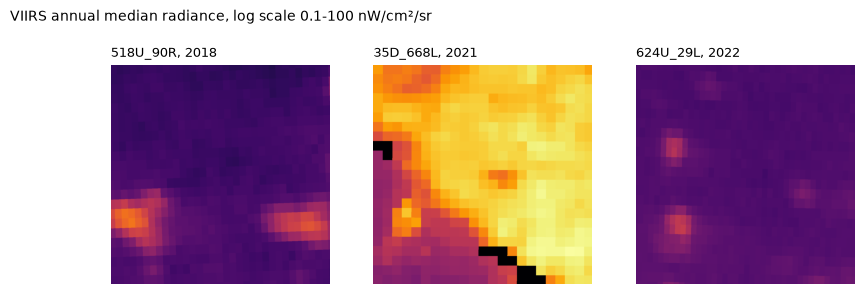

In [21]:
import pyarrow.parquet as pq
import rasterio

VIIRS = "https://huggingface.co/datasets/Major-TOM/Core-VIIRS-Nighttime-Light/resolve/main/"
ids = [f"MT10_{g}" for g in cells.grid_cell.unique()]
index = pq.read_table(f"{VIIRS}INDEX.parquet", filesystem=https, columns=["id", "year", "shard", "offset", "size"],
                      filters=[("id", "in", ids)]).to_pandas()
fig, axes = plt.subplots(1, len(index), figsize=(3.2 * len(index), 3.4), squeeze=False)
for ax, tile in zip(axes[0], index.itertuples()):
    with rasterio.open(f"/vsisubfile/{tile.offset}_{tile.size},/vsicurl/{VIIRS}{tile.shard}") as src:
        radiance = src.read(1)                                       # nW/cm²/sr, 1,056 x 1,056 at 10 m
    ax.imshow(np.log10(np.clip(radiance, 0.1, 100)), cmap="inferno", vmin=-1, vmax=2), ax.axis("off")
    ax.set_title(f"{tile.id[5:]}, {tile.year}", loc="left", fontsize=9)
fig.suptitle("VIIRS annual median radiance, log scale 0.1-100 nW/cm²/sr", x=0.02, ha="left", fontsize=10);

Core-Weather holds the weather around each Core acquisition (section 7 lists its sources). `acquisitions.parquet`
links a Core sample (`dataset`, `product_id`) to its acquisition time; the rows are in that day's file.

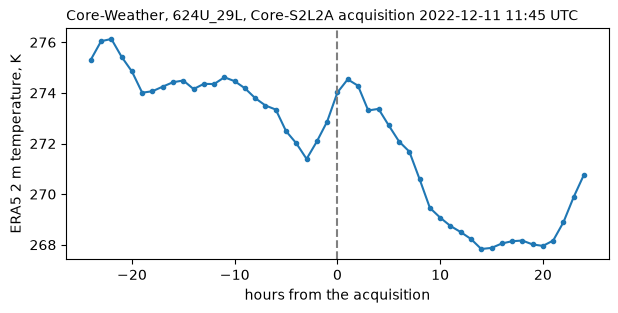

In [22]:
WEATHER = "https://data.source.coop/major-tom/core-weather"
sample = meta.iloc[0]
links = pd.read_parquet(f"{WEATHER}/acquisitions.parquet", filesystem=https,
                        filters=[("grid_cell", "=", sample.grid_cell), ("dataset", "=", "Core-S2L2A")])
pick = links[links.product_id == sample.product_id].iloc[0]          # the Core-S2L2A sample shown above
day = f"year={pick.acquired:%Y}/{pick.acquired:%Y-%m-%d}.parquet"     # files are split by acquisition day
here = [("grid_cell", "=", pick.grid_cell), ("acquired", "=", pick.acquired)]
hourly = pd.read_parquet(f"{WEATHER}/hourly/{day}", filesystem=https, filters=here,
                         columns=["step_h", "era5_t2m"]).sort_values("step_h")
ax = hourly.plot(x="step_h", y="era5_t2m", figsize=(7, 3), legend=False, marker=".")
ax.axvline(0, color="grey", ls="--"), ax.set_xlabel("hours from the acquisition"), ax.set_ylabel("ERA5 2 m temperature, K")
ax.set_title(f"Core-Weather, {pick.grid_cell}, Core-S2L2A acquisition {pick.acquired:%Y-%m-%d %H:%M} UTC", loc="left", fontsize=10);

## 9. More

- [Legacy notebook 05](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/legacy/05-Generate-Major-TOM-Embeddings.ipynb): embeddings with `majortom.embedder`
  (SigLIP, DINOv2, SSL4EO; needs `majortom[embed]` and a GPU).
- [SPEC.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/SPEC.md): the grid and the window rule for any spacing and resolution.
- [ARCHIVES.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/ARCHIVES.md), [RELEASE.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/RELEASE.md), [CLIMATE.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/CLIMATE.md):
  products and archives, the release format, the climate datasets.
- Apps, each a Hugging Face Space ([apps/README.md](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/apps/README.md)):
  - [Core Viewer](https://huggingface.co/spaces/Major-TOM/MajorTOM-Core-Viewer): one Core sample at a place or found
    by a text prompt; Sentinel-2, Sentinel-1, DEM, AlphaEarth, VIIRS.
  - [Raster Viewer](https://huggingface.co/spaces/Major-TOM/MajorTOM-Raster-Viewer) (private for now): where each Core
    dataset has samples, on a globe; a clicked cell's sample, VIIRS tile, AlphaEarth embedding and Core-Weather.
  - [Climate Globe](https://huggingface.co/spaces/Major-TOM/MajorTOM-Climate-Globe) (private for now): the monthly
    climate datasets on a globe; monthly maps, normals, one cell's series.
- [skills/major-tom](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/skills/major-tom/SKILL.md): an agent skill for working with Major TOM.